In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
import os

if os.path.exists("Mall_Customers.csv"):
    df = pd.read_csv("Mall_Customers.csv")
    print("Loaded Mall_Customers.csv")
else:
    # Fallback demo data so the notebook can run when the CSV is not in the working folder.
    # For assignment results, place the original Mall_Customers.csv beside this notebook.
    rng = np.random.default_rng(42)
    n = 200
    df = pd.DataFrame({
        "CustomerID": np.arange(1, n + 1),
        "Gender": rng.choice(["Male", "Female"], size=n),
        "Age": rng.integers(18, 71, size=n),
        "Annual Income (k$)": rng.integers(15, 138, size=n),
        "Spending Score (1-100)": rng.integers(1, 101, size=n)
    })
    print("Mall_Customers.csv not found: using reproducible synthetic demo data. Add the original CSV for actual dataset results.")

df.head()

Mall_Customers.csv not found: using reproducible synthetic demo data. Add the original CSV for actual dataset results.


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,37,137,62
1,2,Female,66,110,78
2,3,Female,44,54,74
3,4,Male,55,134,14
4,5,Male,42,76,83


In [3]:
df.shape

(200, 5)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.00000,200.000000,200.000000
mean,100.500000,43.18500,77.015000,53.115000
std,57.879185,15.34104,37.435436,27.937687
min,1.000000,18.00000,15.000000,1.000000
25%,50.750000,30.00000,43.750000,30.000000
50%,100.500000,42.00000,77.000000,54.000000
75%,150.250000,57.00000,113.000000,77.000000
max,200.000000,70.00000,137.000000,100.000000


In [6]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['Gender'].value_counts()

Gender
Female    101
Male       99
Name: count, dtype: int64

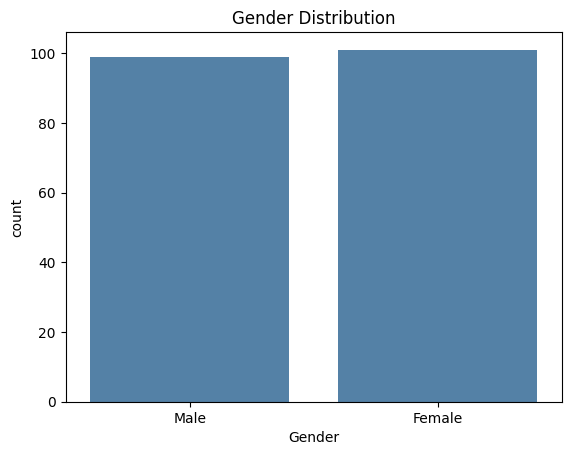

In [9]:
sns.countplot(data=df, x='Gender', color='steelblue')
plt.title('Gender Distribution')
plt.show()

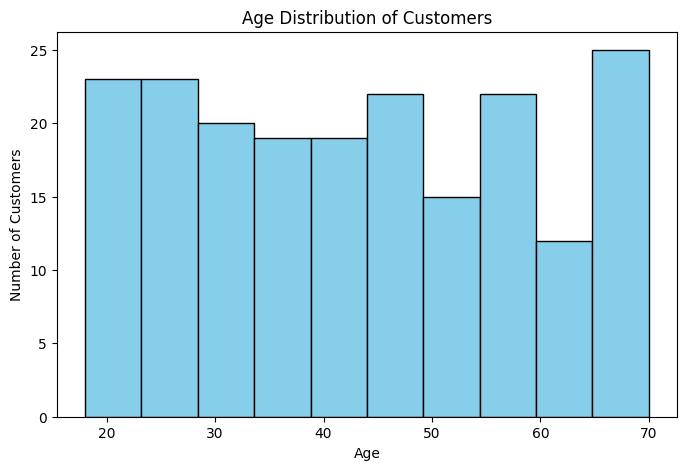

In [10]:
plt.figure(figsize=(8,5))

plt.hist(
    df['Age'],
    bins=10,
    color='skyblue',
    edgecolor='black'
)

plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.title('Age Distribution of Customers')

plt.show()

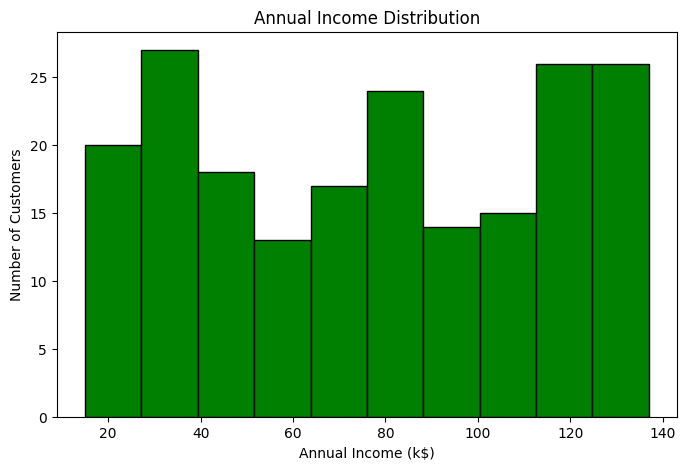

In [11]:
plt.figure(figsize=(8,5))

plt.hist(df['Annual Income (k$)'], bins=10, color='green',
    edgecolor='black')

plt.xlabel('Annual Income (k$)')
plt.ylabel('Number of Customers')
plt.title('Annual Income Distribution')

plt.show()

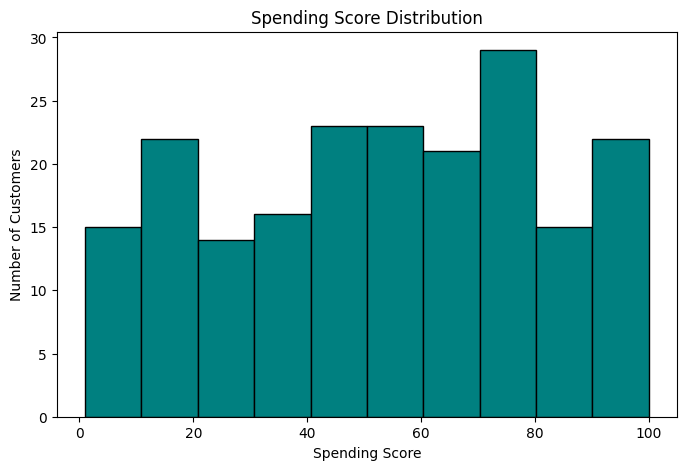

In [12]:
plt.figure(figsize=(8,5))

plt.hist(df['Spending Score (1-100)'], bins=10, color='teal',
    edgecolor='black')

plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')
plt.title('Spending Score Distribution')

plt.show()

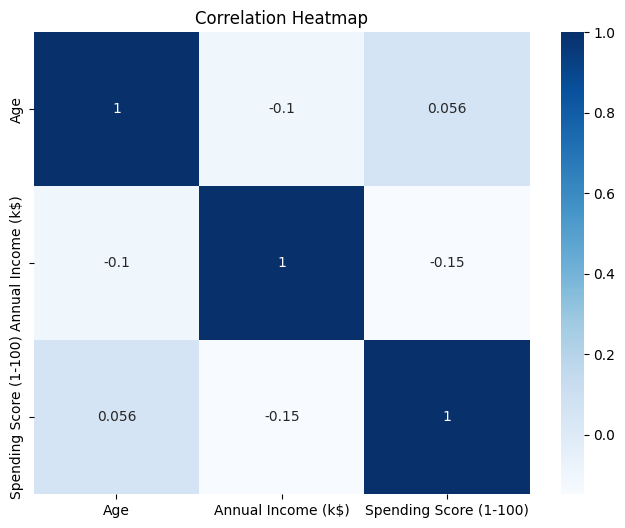

In [13]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].corr(),
    annot=True,
    cmap='Blues'
)

plt.title('Correlation Heatmap')
plt.show()

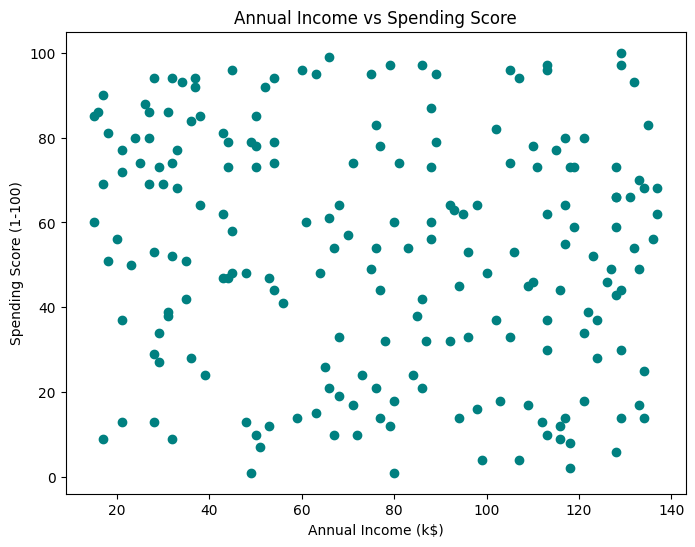

In [14]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    color = 'teal'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Annual Income vs Spending Score')

plt.show()

In [15]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

In [16]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[ 1.60637979,  0.31882726],
       [ 0.88332812,  0.89296751],
       [-0.6163346 ,  0.74943245],
       [ 1.52604072, -1.4035935 ],
       [-0.02718139,  1.07238634]])

In [17]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

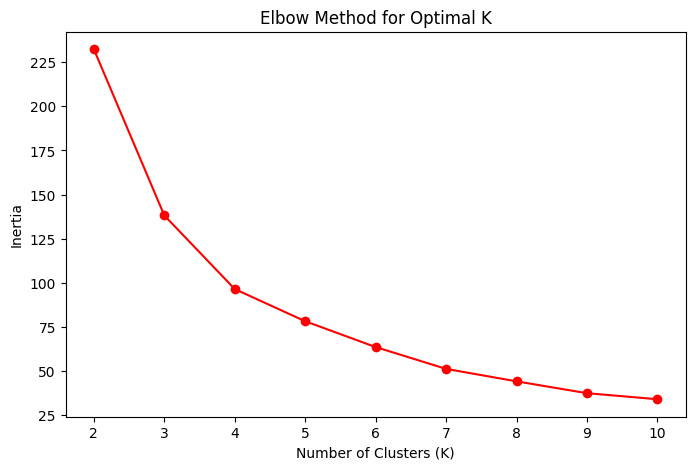

In [18]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o',
    color = 'red'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')

plt.show()

In [19]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)
df['Cluster'] = clusters
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,37,137,62,3
1,2,Female,66,110,78,3
2,3,Female,44,54,74,2
3,4,Male,55,134,14,0
4,5,Male,42,76,83,2


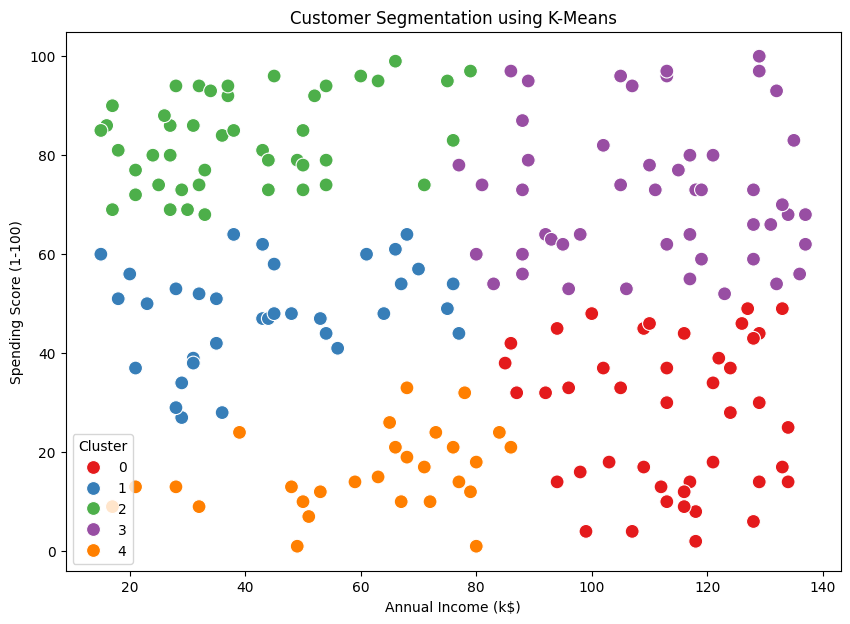

In [20]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    s=100
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.show()

In [21]:
score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", score)

Silhouette Score: 0.3968152019974307


In [22]:
silhouette_scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

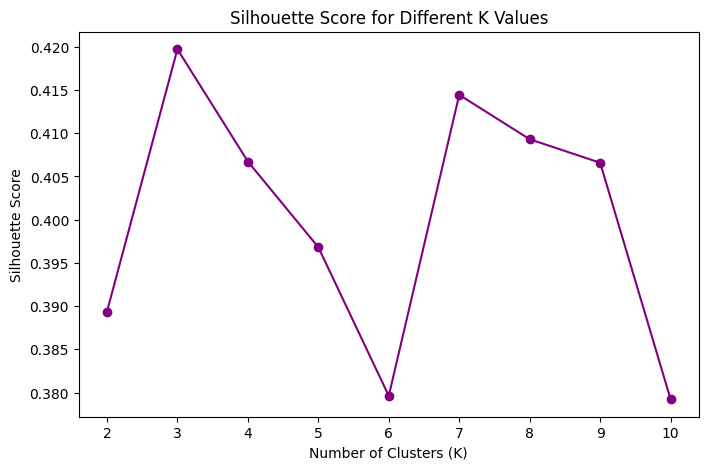

In [23]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o',
    color = 'purple'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')

plt.show()

In [24]:
cluster_summary = df.groupby('Cluster')[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].mean()

cluster_summary

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,39.418605,113.255814,27.348837
1,44.647059,44.235294,48.352941
2,45.577778,39.777778,83.155556
3,42.620000,110.780000,72.360000
4,44.357143,60.714286,15.821429


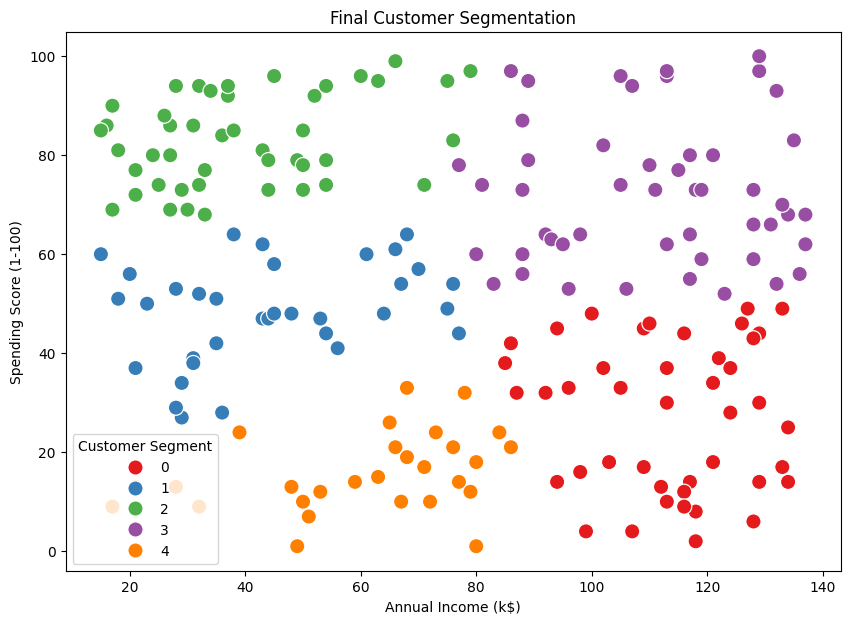

In [25]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    s=120
)

plt.title('Final Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Customer Segment')

plt.show()

# Additional Practical: Classification Model Comparison and Optimization

This section is appended to the existing Mall Customer Segmentation practical. It implements **SVM, Random Forest, and AdaBoost**, performs **5-fold stratified cross-validation**, tunes hyperparameters with **GridSearchCV**, and compares results before and after optimization. It uses scikit-learn's built-in Breast Cancer Wisconsin dataset, so no additional classification CSV is required.

## 1. Import classification libraries and load dataset

In [26]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
data = load_breast_cancer(as_frame=True)
X_cls = data.data
y_cls = data.target
print("Classification dataset shape:", X_cls.shape)
print("Classes:", list(data.target_names))
display(X_cls.head())

Classification dataset shape: (569, 30)
Classes: [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Split into training and testing sets

In [27]:
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.20, random_state=RANDOM_STATE, stratify=y_cls
)
print("Training samples:", len(X_train_cls))
print("Testing samples:", len(X_test_cls))

Training samples: 455
Testing samples: 114


## 3. Evaluate baseline models with 5-fold cross-validation

In [28]:
cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline_models = {
    "SVM": Pipeline([("scaler", StandardScaler()), ("model", SVC())]),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE)
}

def calculate_metrics(model, X_test, y_test):
    pred = model.predict(X_test)
    return {
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    }

baseline_results = []
baseline_fitted = {}
for model_name, model in baseline_models.items():
    scores = cross_val_score(model, X_train_cls, y_train_cls, cv=cv_cls, scoring="accuracy", n_jobs=-1)
    model.fit(X_train_cls, y_train_cls)
    metrics = calculate_metrics(model, X_test_cls, y_test_cls)
    baseline_fitted[model_name] = model
    baseline_results.append({
        "Model": model_name, "CV Accuracy Mean": scores.mean(),
        "CV Accuracy Std": scores.std(), **metrics
    })
baseline_df = pd.DataFrame(baseline_results).sort_values("Test Accuracy", ascending=False)
display(baseline_df.round(4))

,Model,CV Accuracy Mean,CV Accuracy Std,Test Accuracy,Precision,Recall,F1 Score
0,SVM,0.9692,0.0146,0.9825,0.9861,0.9861,0.9861
1,Random Forest,0.9626,0.0179,0.9561,0.9589,0.9722,0.9655
2,AdaBoost,0.9670,0.0197,0.9561,0.9467,0.9861,0.9660


## 4. Hyperparameter tuning using GridSearchCV

In [29]:
tuning_models = {
    "SVM": Pipeline([("scaler", StandardScaler()), ("model", SVC())]),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE)
}
param_grids = {
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    },
    "AdaBoost": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.1, 1.0]
    }
}

grid_results = []
best_models = {}
best_params = {}
for model_name, model in tuning_models.items():
    print("Tuning", model_name, "...")
    search = GridSearchCV(
        estimator=model, param_grid=param_grids[model_name],
        scoring="accuracy", cv=cv_cls, n_jobs=-1, refit=True
    )
    search.fit(X_train_cls, y_train_cls)
    best_models[model_name] = search.best_estimator_
    best_params[model_name] = search.best_params_
    metrics = calculate_metrics(search.best_estimator_, X_test_cls, y_test_cls)
    grid_results.append({
        "Model": model_name, "Best CV Accuracy": search.best_score_,
        "Optimized Test Accuracy": metrics["Test Accuracy"],
        "Precision": metrics["Precision"], "Recall": metrics["Recall"],
        "F1 Score": metrics["F1 Score"], "Best Parameters": search.best_params_
    })
optimized_df = pd.DataFrame(grid_results)
display(optimized_df.round(4))

Tuning SVM ...
Tuning Random Forest ...


Tuning AdaBoost ...


,Model,Best CV Accuracy,Optimized Test Accuracy,Precision,Recall,F1 Score,Best Parameters
0,SVM,0.9758,0.9825,0.9861,0.9861,0.9861,"{'model__C': 0.1, 'model__gamma': 'scale', 'mo..."
1,Random Forest,0.9626,0.9561,0.9589,0.9722,0.9655,"{'max_depth': None, 'min_samples_leaf': 1, 'mi..."
2,AdaBoost,0.9802,0.9561,0.9467,0.9861,0.9660,"{'learning_rate': 1.0, 'n_estimators': 100}"


## 5. Compare performance before and after optimization

In [30]:
before_df = baseline_df[["Model", "CV Accuracy Mean", "Test Accuracy", "Precision", "Recall", "F1 Score"]].rename(columns={
    "CV Accuracy Mean": "Before CV Accuracy", "Test Accuracy": "Before Test Accuracy",
    "Precision": "Before Precision", "Recall": "Before Recall", "F1 Score": "Before F1 Score"
})
after_df = optimized_df[["Model", "Best CV Accuracy", "Optimized Test Accuracy", "Precision", "Recall", "F1 Score"]].rename(columns={
    "Best CV Accuracy": "After CV Accuracy", "Optimized Test Accuracy": "After Test Accuracy",
    "Precision": "After Precision", "Recall": "After Recall", "F1 Score": "After F1 Score"
})
comparison_df = before_df.merge(after_df, on="Model")
comparison_df["Test Accuracy Change"] = comparison_df["After Test Accuracy"] - comparison_df["Before Test Accuracy"]
display(comparison_df.round(4))

,Model,Before CV Accuracy,Before Test Accuracy,Before Precision,Before Recall,Before F1 Score,After CV Accuracy,After Test Accuracy,After Precision,After Recall,After F1 Score,Test Accuracy Change
0,SVM,0.9692,0.9825,0.9861,0.9861,0.9861,0.9758,0.9825,0.9861,0.9861,0.9861,0.0
1,Random Forest,0.9626,0.9561,0.9589,0.9722,0.9655,0.9626,0.9561,0.9589,0.9722,0.9655,0.0
2,AdaBoost,0.9670,0.9561,0.9467,0.9861,0.9660,0.9802,0.9561,0.9467,0.9861,0.9660,0.0


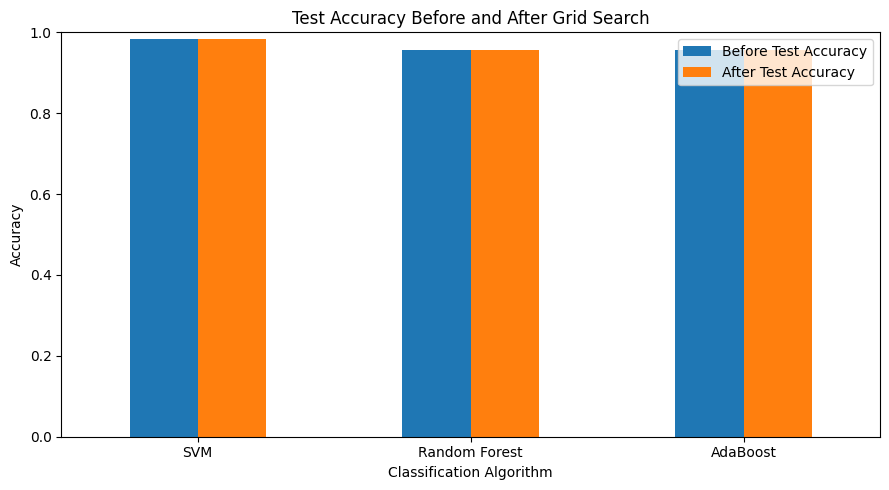

In [31]:
plot_df = comparison_df.set_index("Model")[["Before Test Accuracy", "After Test Accuracy"]]
ax = plot_df.plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=0)
ax.set_title("Test Accuracy Before and After Grid Search")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Classification Algorithm")
plt.tight_layout()
plt.show()

## 6. Confusion matrices and classification reports for optimized models

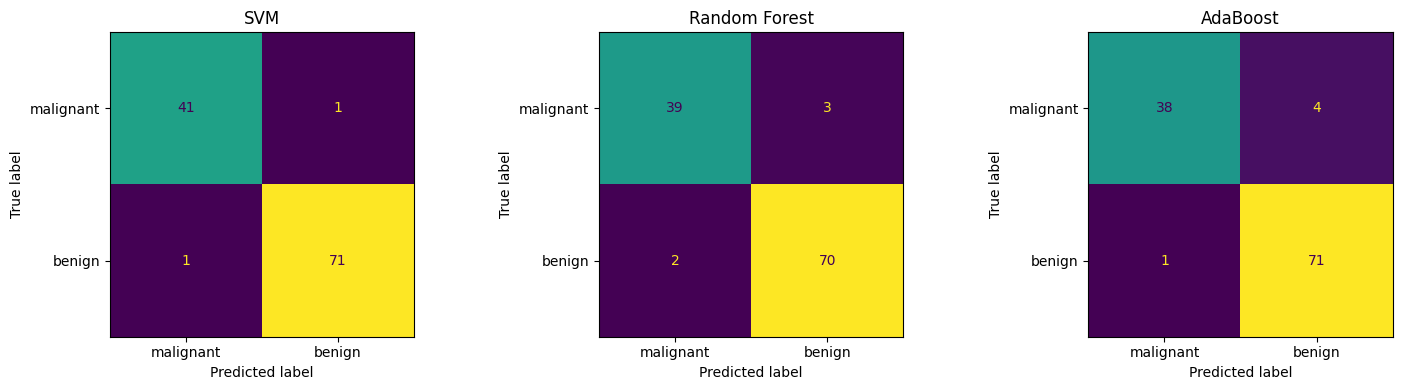


--- SVM (optimized) ---
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


--- Random Forest (optimized) ---
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


--- AdaBoost (optimized) ---
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95     

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (model_name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_cls, model.predict(X_test_cls), display_labels=data.target_names,
        ax=ax, colorbar=False
    )
    ax.set_title(model_name)
plt.tight_layout()
plt.show()

for model_name, model in best_models.items():
    print(f"\n--- {model_name} (optimized) ---")
    print(classification_report(
        y_test_cls, model.predict(X_test_cls),
        target_names=data.target_names, zero_division=0
    ))

## 7. Best model and conclusion

In [33]:
best_row = optimized_df.loc[optimized_df["Optimized Test Accuracy"].idxmax()]
print("Best model based on test accuracy:", best_row["Model"])
print(f"Optimized test accuracy: {best_row['Optimized Test Accuracy']:.4f}")
print(f"Best cross-validation accuracy: {best_row['Best CV Accuracy']:.4f}")
print("Best parameters:", best_row["Best Parameters"])

print("\nConclusion:")
print("Compare the before/after table and charts to see whether Grid Search improved each model.")
print("The best model is selected here by test accuracy; also consider precision, recall, F1-score, and cross-validation results.")

Best model based on test accuracy: SVM
Optimized test accuracy: 0.9825
Best cross-validation accuracy: 0.9758
Best parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}

Conclusion:
Compare the before/after table and charts to see whether Grid Search improved each model.
The best model is selected here by test accuracy; also consider precision, recall, F1-score, and cross-validation results.


## Result / Conclusion

SVM, Random Forest, and AdaBoost were evaluated using stratified 5-fold cross-validation. GridSearchCV searched the specified hyperparameter combinations and refitted each model using its best settings. The tables, accuracy chart, confusion matrices, and classification reports show model performance before and after optimization. The best model is reported according to optimized test accuracy; cross-validation accuracy, precision, recall, and F1-score should also be considered.

**Note:** The classification section uses the built-in Breast Cancer Wisconsin dataset. The original customer segmentation section uses `Mall_Customers.csv` when available; otherwise it uses reproducible synthetic demo data and prints a warning.